# **English → Tamil Machine Translation using a Transformer**


## 1. Install dependencies

In [2]:
!pip -q install datasets sacrebleu sentencepiece

## 2. Import libraries and configure the device

In [3]:
import re
import math
import time
import random
import unicodedata
from itertools import islice

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import LambdaLR

from datasets import load_dataset
from sklearn.model_selection import train_test_split
import sentencepiece as spm
from sacrebleu.metrics import BLEU, CHRF

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("PyTorch:", torch.__version__)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not detected. Training will be much slower on CPU.")

Device: cuda
PyTorch: 2.14.1+cu130
GPU: Tesla T4


## 3. Load an English–Tamil parallel dataset

In [4]:
DATASET_NAME = "gopi30/english-tamil"
SPLIT = "train"
SOURCE_COLUMN = "en"
TARGET_COLUMN = "ta"

# Number of sentence pairs to collect. More data = better translations but longer training.
# (Your first run used 30,000, which is too little for a Transformer to learn Tamil well.)
MAX_SAMPLES = 100_000

stream = load_dataset(DATASET_NAME, split=SPLIT, streaming=True)
first_row = next(iter(stream))
print("First row preview:")
print(first_row)
print("Available columns:", list(first_row.keys()))
assert SOURCE_COLUMN in first_row and TARGET_COLUMN in first_row, "Update SOURCE_COLUMN / TARGET_COLUMN"

README.md:   0%|          | 0.00/1.24k [00:00<?, ?B/s]

First row preview:
{'en': 'Some 14 months later, the second calf is born.', 'ta': 'சுமார் 14 மாதங்கள் கழித்து, இரண்டாம் கன்றை ஈனுகிறது.'}
Available columns: ['en', 'ta']


## 4. Collect a manageable, shuffled subset

In [5]:
# A fresh stream, shuffled with a buffer so we don't just take the first (possibly same-domain) rows.
stream = load_dataset(DATASET_NAME, split=SPLIT, streaming=True)
stream = stream.shuffle(seed=SEED, buffer_size=20_000)

rows = [
    {"English": r[SOURCE_COLUMN], "Tamil": r[TARGET_COLUMN]}
    for r in islice(stream, MAX_SAMPLES)
]

df = pd.DataFrame(rows)
print("Raw dataset shape:", df.shape)
display(df.head())

Raw dataset shape: (100000, 2)


,English,Tamil
0,Interest in social work,சமூக சேவையில் ஆர்வம்
1,It is approximately 10 km from this village.,இந்த கிராமம் 10 கி.
2,More than 40 people have died.,அதில் 40க்கும் மேற்பட்ட வீரர்கள் உயிரிழந்துள்ள...
3,Widening the existing bridge at km 3/4 of Moun...,மவுண்ட்-பூவிருந்தவல்லி ஆவடி சாலை (மா.நெ.55) கி...
4,"After he died, the Emperor Shah Jahan forced S...","அவர் இறந்த பிறகு, பேரரசர் ஷாஜகான் இவரிடம் நகைக..."


## 5. Clean and filter the parallel data

In [6]:
URL_RE = re.compile(r"http\S+|www\.\S+")
TAG_RE = re.compile(r"<[^>]+>")
ZERO_WIDTH_RE = re.compile(r"[\u200b\u200c\u200d\ufeff]")
CONTROL_RE = re.compile(r"[\x00-\x1f\x7f]")
SPACE_RE = re.compile(r"\s+")


def clean_text(text):
    """Light cleaning shared by English and Tamil. Case and punctuation are kept;
    the subword tokenizer handles everything else."""
    text = unicodedata.normalize("NFKC", str(text))
    text = URL_RE.sub(" ", text)
    text = TAG_RE.sub(" ", text)
    text = ZERO_WIDTH_RE.sub("", text)
    text = CONTROL_RE.sub(" ", text)
    return SPACE_RE.sub(" ", text).strip()


def script_fraction(text, lo, hi):
    """Fraction of letters/marks whose code point lies in [lo, hi]."""
    chars = [c for c in text if unicodedata.category(c)[0] in "LM"]
    if not chars:
        return 0.0
    return sum(lo <= ord(c) <= hi for c in chars) / len(chars)


df = df.dropna(subset=["English", "Tamil"]).copy()
df["English"] = df["English"].apply(clean_text)
df["Tamil"] = df["Tamil"].apply(clean_text)
df = df[(df["English"] != "") & (df["Tamil"] != "")]
n0 = len(df)

# Keep only pairs where each side is mostly in the expected script (drops wrong-language / noisy rows).
en_ok = df["English"].apply(lambda s: script_fraction(s, 0x0041, 0x007A) >= 0.90)
ta_ok = df["Tamil"].apply(lambda s: script_fraction(s, 0x0B80, 0x0BFF) >= 0.60)
df = df[en_ok & ta_ok]

# Sentence-length filters (in words) + length-ratio filter to drop badly misaligned pairs.
en_len = df["English"].str.split().str.len()
ta_len = df["Tamil"].str.split().str.len()
ratio = en_len / ta_len
df = df[en_len.between(2, 60) & ta_len.between(2, 60) & ratio.between(0.4, 4.0)]

# Remove duplicates on either side (also reduces train/test leakage).
df = df.drop_duplicates(subset=["English"]).drop_duplicates(subset=["Tamil"]).reset_index(drop=True)

print(f"Before filtering: {n0} | After filtering: {len(df)}")
display(df.head(10))

Before filtering: 100000 | After filtering: 91028


,English,Tamil
0,Interest in social work,சமூக சேவையில் ஆர்வம்
1,It is approximately 10 km from this village.,இந்த கிராமம் 10 கி.
2,More than 40 people have died.,அதில் 40க்கும் மேற்பட்ட வீரர்கள் உயிரிழந்துள்ள...
3,Widening the existing bridge at km 3/4 of Moun...,மவுண்ட்-பூவிருந்தவல்லி ஆவடி சாலை (மா.நெ.55) கி...
4,"After he died, the Emperor Shah Jahan forced S...","அவர் இறந்த பிறகு, பேரரசர் ஷாஜகான் இவரிடம் நகைக..."
5,This is their first film together.,இருவரும் இணையும் முதல் படம் இது.
6,They were also provided snacks and food.,"மேலும், அவர்களுக்கு மளிகை, காய்கறி உள்ளிட்ட பொ..."
7,It would be discernible only with the eyes of ...,வேதத்திலுள்ள எந்தத் தீர்க்கதரிசனமும் சுயதோற்றம...
8,Which novel did you read last?,சமீபத்தில் வாசித்த நூல் எது?
9,The two often meet.,இருவரும் அடிக்கடி நேரில் சந்தித்துக் கொண்டு தா...


## 6. Split into train, validation and test sets

In [7]:
train_df, temp_df = train_test_split(df, test_size=0.10, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 81925
Validation: 4551
Test: 4552


## 7. Train a joint SentencePiece subword tokenizer (on the training split only)

In [8]:
VOCAB_SIZE = 16000

with open("spm_train.txt", "w", encoding="utf-8") as f:
    for sentence in train_df["English"]:
        f.write(sentence + "\n")
    for sentence in train_df["Tamil"]:
        f.write(sentence + "\n")

spm.SentencePieceTrainer.train(
    input="spm_train.txt",
    model_prefix="spm_en_ta",
    vocab_size=VOCAB_SIZE,
    model_type="unigram",
    character_coverage=1.0,          # keep every Tamil character
    pad_id=0, unk_id=1, bos_id=2, eos_id=3,
    pad_piece="<pad>", unk_piece="<unk>", bos_piece="<s>", eos_piece="</s>",
    hard_vocab_limit=False,
    shuffle_input_sentence=True,
)

sp = spm.SentencePieceProcessor(model_file="spm_en_ta.model")
PAD_ID, UNK_ID, BOS_ID, EOS_ID = sp.pad_id(), sp.unk_id(), sp.bos_id(), sp.eos_id()
vocab_size = sp.get_piece_size()
print("Vocabulary size:", vocab_size)

# Sanity check: examples and <unk> rate (should be ~0%).
example_en, example_ta = train_df["English"].iloc[0], train_df["Tamil"].iloc[0]
print("\nEnglish:", example_en)
print("Pieces :", sp.encode(example_en, out_type=str))
print("Tamil  :", example_ta)
print("Pieces :", sp.encode(example_ta, out_type=str))

sample = train_df.sample(min(2000, len(train_df)), random_state=SEED)
for col in ["English", "Tamil"]:
    ids = sp.encode(sample[col].tolist())
    total = sum(len(x) for x in ids)
    unk = sum(x.count(UNK_ID) for x in ids)
    print(f"{col}: avg {total / len(ids):.1f} tokens/sentence, <unk> rate {100 * unk / total:.3f}%")

Vocabulary size: 16000

English: There are hills there.
Pieces : ['▁There', '▁are', '▁hill', 's', '▁there', '.']
Tamil  : அங்கே சோலைவனங்கள் உள்ளன.
Pieces : ['▁அங்கே', '▁சோ', 'லை', 'வன', 'ங்கள்', '▁உள்ளன', '.']
English: avg 16.4 tokens/sentence, <unk> rate 0.000%
Tamil: avg 15.8 tokens/sentence, <unk> rate 0.000%


## 8. Encode sentences and create Dataset / DataLoaders

In [9]:
MAX_LEN = 128   # maximum tokens per sentence (including <eos>/<bos>)


def encode_pairs(dataframe):
    """Returns (src_ids + <eos>, <bos> + tgt_ids + <eos>) pairs.
    Pairs that would not fit in MAX_LEN are dropped (not silently truncated)."""
    src_all = sp.encode(dataframe["English"].tolist())
    tgt_all = sp.encode(dataframe["Tamil"].tolist())
    pairs, dropped = [], 0
    for s, t in zip(src_all, tgt_all):
        if len(s) + 1 > MAX_LEN or len(t) + 2 > MAX_LEN:
            dropped += 1
            continue
        pairs.append((s + [EOS_ID], [BOS_ID] + t + [EOS_ID]))
    return pairs, dropped


class TranslationDataset(Dataset):
    def __init__(self, pairs):
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        src, tgt = self.pairs[index]
        return torch.tensor(src, dtype=torch.long), torch.tensor(tgt, dtype=torch.long)


def collate_fn(batch):
    sources, targets = zip(*batch)
    sources = nn.utils.rnn.pad_sequence(sources, batch_first=True, padding_value=PAD_ID)
    targets = nn.utils.rnn.pad_sequence(targets, batch_first=True, padding_value=PAD_ID)
    return sources, targets


BATCH_SIZE = 64
loaders = {}
for name, frame in [("train", train_df), ("val", val_df), ("test", test_df)]:
    pairs, dropped = encode_pairs(frame)
    print(f"{name}: {len(pairs)} pairs kept, {dropped} dropped for length")
    loaders[name] = DataLoader(
        TranslationDataset(pairs),
        batch_size=BATCH_SIZE,
        shuffle=(name == "train"),
        collate_fn=collate_fn,
        pin_memory=(device.type == "cuda"),
    )
train_loader, val_loader, test_loader = loaders["train"], loaders["val"], loaders["test"]

src_example, tgt_example = next(iter(train_loader))
print("Batch shapes:", tuple(src_example.shape), tuple(tgt_example.shape))
print("Train batches:", len(train_loader))

train: 81916 pairs kept, 9 dropped for length
val: 4548 pairs kept, 3 dropped for length
test: 4550 pairs kept, 2 dropped for length
Batch shapes: (64, 50) (64, 40)
Train batches: 1280


## 9. Implement the Transformer from scratch

In [10]:
class PositionalEncoding(nn.Module):
    """Fixed sinusoidal positional encoding."""

    def __init__(self, d_model, dropout=0.1, max_len=512):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float) * (-math.log(10000.0) / d_model)
        )
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return self.dropout(x + self.pe[:, : x.size(1), :])


class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, nhead, dropout=0.1):
        super().__init__()
        assert d_model % nhead == 0, "d_model must be divisible by nhead"
        self.nhead = nhead
        self.d_k = d_model // nhead
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, query, key, value, mask=None):
        # mask: bool tensor broadcastable to (B, nhead, Tq, Tk); True = may attend, False = blocked.
        B, Tq, _ = query.shape
        Tk = key.size(1)
        q = self.q_proj(query).view(B, Tq, self.nhead, self.d_k).transpose(1, 2)
        k = self.k_proj(key).view(B, Tk, self.nhead, self.d_k).transpose(1, 2)
        v = self.v_proj(value).view(B, Tk, self.nhead, self.d_k).transpose(1, 2)

        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.d_k)
        if mask is not None:
            scores = scores.masked_fill(~mask, torch.finfo(scores.dtype).min)
        attn = self.dropout(torch.softmax(scores, dim=-1))

        out = torch.matmul(attn, v).transpose(1, 2).contiguous().view(B, Tq, -1)
        return self.out_proj(out)


class FeedForward(nn.Module):
    def __init__(self, d_model, dim_ff, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, dim_ff), nn.ReLU(), nn.Dropout(dropout), nn.Linear(dim_ff, d_model)
        )

    def forward(self, x):
        return self.net(x)


class EncoderLayer(nn.Module):
    def __init__(self, d_model, nhead, dim_ff, dropout):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, nhead, dropout)
        self.ff = FeedForward(d_model, dim_ff, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, src_mask):
        h = self.norm1(x)
        x = x + self.dropout(self.self_attn(h, h, h, src_mask))
        x = x + self.dropout(self.ff(self.norm2(x)))
        return x


class DecoderLayer(nn.Module):
    def __init__(self, d_model, nhead, dim_ff, dropout):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, nhead, dropout)
        self.cross_attn = MultiHeadAttention(d_model, nhead, dropout)
        self.ff = FeedForward(d_model, dim_ff, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, memory, src_mask, tgt_mask):
        h = self.norm1(x)
        x = x + self.dropout(self.self_attn(h, h, h, tgt_mask))
        h = self.norm2(x)
        x = x + self.dropout(self.cross_attn(h, memory, memory, src_mask))
        x = x + self.dropout(self.ff(self.norm3(x)))
        return x


class Transformer(nn.Module):
    def __init__(self, vocab_size, d_model=256, nhead=4, num_layers=3,
                 dim_ff=1024, dropout=0.1, max_len=512):
        super().__init__()
        self.d_model = d_model

        # One embedding table shared by encoder input, decoder input and output projection
        # (valid because English and Tamil share the SentencePiece vocabulary).
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=PAD_ID)
        self.pos_encoding = PositionalEncoding(d_model, dropout, max_len)

        self.encoder_layers = nn.ModuleList(
            [EncoderLayer(d_model, nhead, dim_ff, dropout) for _ in range(num_layers)]
        )
        self.decoder_layers = nn.ModuleList(
            [DecoderLayer(d_model, nhead, dim_ff, dropout) for _ in range(num_layers)]
        )
        self.encoder_norm = nn.LayerNorm(d_model)
        self.decoder_norm = nn.LayerNorm(d_model)

        self.out_proj = nn.Linear(d_model, vocab_size, bias=False)
        self._init_weights()
        self.out_proj.weight = self.embedding.weight   # weight tying

    def _init_weights(self):
        for module in self.modules():
            if isinstance(module, nn.Linear):
                nn.init.xavier_uniform_(module.weight)
                if module.bias is not None:
                    nn.init.zeros_(module.bias)
        nn.init.normal_(self.embedding.weight, mean=0.0, std=self.d_model ** -0.5)
        with torch.no_grad():
            self.embedding.weight[PAD_ID].zero_()

    def embed(self, tokens):
        return self.pos_encoding(self.embedding(tokens) * math.sqrt(self.d_model))

    def encode(self, src, src_mask):
        x = self.embed(src)
        for layer in self.encoder_layers:
            x = layer(x, src_mask)
        return self.encoder_norm(x)

    def decode(self, tgt, memory, src_mask, tgt_mask):
        x = self.embed(tgt)
        for layer in self.decoder_layers:
            x = layer(x, memory, src_mask, tgt_mask)
        return self.decoder_norm(x)

    def forward(self, src, tgt):
        src_mask = make_src_mask(src)
        tgt_mask = make_tgt_mask(tgt)
        memory = self.encode(src, src_mask)
        return self.out_proj(self.decode(tgt, memory, src_mask, tgt_mask))


def make_src_mask(src):
    """(B, 1, 1, S) — True where the source token is not padding."""
    return (src != PAD_ID).unsqueeze(1).unsqueeze(2)


def make_tgt_mask(tgt):
    """(B, 1, T, T) — causal mask AND padding mask. True = allowed."""
    T = tgt.size(1)
    pad_mask = (tgt != PAD_ID).unsqueeze(1).unsqueeze(2)
    causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=tgt.device)).unsqueeze(0).unsqueeze(0)
    return pad_mask & causal


# Hyperparameters
D_MODEL, NHEAD, NUM_LAYERS, DIM_FF, DROPOUT = 256, 4, 3, 1024, 0.1

model = Transformer(
    vocab_size=vocab_size, d_model=D_MODEL, nhead=NHEAD,
    num_layers=NUM_LAYERS, dim_ff=DIM_FF, dropout=DROPOUT,
).to(device)

print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")

Total parameters: 9,626,624


## 10. Loss function, optimizer and learning-rate schedule

In [11]:
EPOCHS = 20
PEAK_LR = 7e-4
WARMUP_STEPS = 2000
LABEL_SMOOTHING = 0.1
PATIENCE = 4                      # stop if validation loss does not improve for this many epochs

# Training loss uses label smoothing; the "sum" criterion gives the true per-token NLL for reporting.
criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID, label_smoothing=LABEL_SMOOTHING)
nll_sum = nn.CrossEntropyLoss(ignore_index=PAD_ID, reduction="sum")

optimizer = torch.optim.Adam(model.parameters(), lr=PEAK_LR, betas=(0.9, 0.98), eps=1e-9)


def lr_lambda(step):
    step = max(1, step)
    return min(step / WARMUP_STEPS, math.sqrt(WARMUP_STEPS / step))   # linear warm-up, then inverse-sqrt decay


scheduler = LambdaLR(optimizer, lr_lambda)

use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
print("Mixed precision:", use_amp)

Mixed precision: True


## 11. Train and validate the model

In [12]:
def train_epoch(model, loader):
    model.train()
    total_nll, total_tokens = 0.0, 0

    for src, tgt in loader:
        src = src.to(device, non_blocking=True)
        tgt = tgt.to(device, non_blocking=True)
        tgt_input, tgt_expected = tgt[:, :-1], tgt[:, 1:]

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logits = model(src, tgt_input)
            loss = criterion(logits.reshape(-1, logits.size(-1)).float(), tgt_expected.reshape(-1))

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        with torch.no_grad():
            total_nll += nll_sum(logits.reshape(-1, logits.size(-1)).float(), tgt_expected.reshape(-1)).item()
            total_tokens += (tgt_expected != PAD_ID).sum().item()

    return total_nll / total_tokens


@torch.no_grad()
def evaluate_loss(model, loader):
    model.eval()
    total_nll, total_tokens = 0.0, 0

    for src, tgt in loader:
        src = src.to(device, non_blocking=True)
        tgt = tgt.to(device, non_blocking=True)
        tgt_input, tgt_expected = tgt[:, :-1], tgt[:, 1:]

        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logits = model(src, tgt_input)
        total_nll += nll_sum(logits.reshape(-1, logits.size(-1)).float(), tgt_expected.reshape(-1)).item()
        total_tokens += (tgt_expected != PAD_ID).sum().item()

    return total_nll / total_tokens


train_losses, val_losses = [], []
best_val_loss = float("inf")
epochs_without_improvement = 0

for epoch in range(EPOCHS):
    start = time.time()
    train_loss = train_epoch(model, train_loader)
    val_loss = evaluate_loss(model, val_loader)
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    improved = val_loss < best_val_loss
    if improved:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        torch.save(model.state_dict(), "best_transformer_state.pt")
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | train NLL {train_loss:.4f} | val NLL {val_loss:.4f} | "
        f"val PPL {math.exp(val_loss):.1f} | {time.time() - start:.0f}s{' *' if improved else ''}"
    )
    if epochs_without_improvement >= PATIENCE:
        print("Early stopping.")
        break

# Restore the best validation checkpoint.
model.load_state_dict(torch.load("best_transformer_state.pt", map_location=device))
print("Best validation NLL:", round(best_val_loss, 4))

Epoch 01/20 | train NLL 7.4149 | val NLL 6.4571 | val PPL 637.2 | 83s *
Epoch 02/20 | train NLL 5.9541 | val NLL 5.3966 | val PPL 220.7 | 84s *
Epoch 03/20 | train NLL 5.2051 | val NLL 4.9610 | val PPL 142.7 | 83s *
Epoch 04/20 | train NLL 4.8131 | val NLL 4.7321 | val PPL 113.5 | 84s *
Epoch 05/20 | train NLL 4.5597 | val NLL 4.5878 | val PPL 98.3 | 83s *
Epoch 06/20 | train NLL 4.3741 | val NLL 4.4931 | val PPL 89.4 | 83s *
Epoch 07/20 | train NLL 4.2280 | val NLL 4.4287 | val PPL 83.8 | 83s *
Epoch 08/20 | train NLL 4.1080 | val NLL 4.3870 | val PPL 80.4 | 83s *
Epoch 09/20 | train NLL 4.0067 | val NLL 4.3504 | val PPL 77.5 | 83s *
Epoch 10/20 | train NLL 3.9190 | val NLL 4.3172 | val PPL 75.0 | 83s *
Epoch 11/20 | train NLL 3.8423 | val NLL 4.3028 | val PPL 73.9 | 87s *
Epoch 12/20 | train NLL 3.7730 | val NLL 4.2842 | val PPL 72.5 | 84s *
Epoch 13/20 | train NLL 3.7110 | val NLL 4.2698 | val PPL 71.5 | 83s *
Epoch 14/20 | train NLL 3.6548 | val NLL 4.2623 | val PPL 71.0 | 83s *
Ep

## 12. Plot training and validation loss

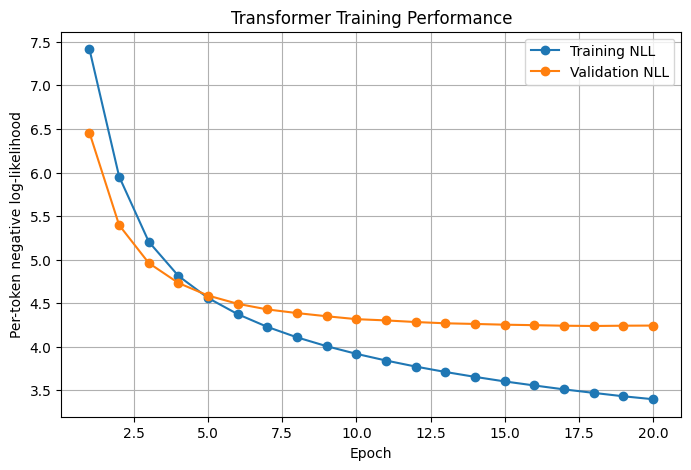

Test NLL: 4.2358 | Test perplexity: 69.1


In [13]:
epochs_range = range(1, len(train_losses) + 1)
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, train_losses, marker="o", label="Training NLL")
plt.plot(epochs_range, val_losses, marker="o", label="Validation NLL")
plt.xlabel("Epoch")
plt.ylabel("Per-token negative log-likelihood")
plt.title("Transformer Training Performance")
plt.legend()
plt.grid(True)
plt.show()

test_loss = evaluate_loss(model, test_loader)
print(f"Test NLL: {test_loss:.4f} | Test perplexity: {math.exp(test_loss):.1f}")

## 13. Decoding (batched greedy search)

In [14]:
@torch.no_grad()
def greedy_decode(model, src, max_len=MAX_LEN):
    """Encodes the source once, then generates tokens step by step for the whole batch."""
    model.eval()
    src_mask = make_src_mask(src)
    memory = model.encode(src, src_mask)

    batch_size = src.size(0)
    ys = torch.full((batch_size, 1), BOS_ID, dtype=torch.long, device=src.device)
    finished = torch.zeros(batch_size, dtype=torch.bool, device=src.device)

    for _ in range(max_len):
        out = model.decode(ys, memory, src_mask, make_tgt_mask(ys))
        logits = model.out_proj(out[:, -1])
        logits[:, [PAD_ID, UNK_ID, BOS_ID]] = float("-inf")     # never generate these
        next_token = logits.argmax(dim=-1)
        next_token = next_token.masked_fill(finished, PAD_ID)
        ys = torch.cat([ys, next_token.unsqueeze(1)], dim=1)
        finished = finished | (next_token == EOS_ID)
        if finished.all():
            break
    return ys[:, 1:]


def ids_to_text(ids):
    keep = []
    for token_id in ids.tolist():
        if token_id == EOS_ID:
            break
        if token_id != PAD_ID:
            keep.append(token_id)
    return sp.decode(keep)          # SentencePiece detokenizes properly (no stray spaces before punctuation)


def translate_batch(sentences, batch_size=64):
    cleaned = [clean_text(s) for s in sentences]
    encoded = [sp.encode(s)[: MAX_LEN - 1] + [EOS_ID] for s in cleaned]
    order = sorted(range(len(encoded)), key=lambda i: len(encoded[i]))   # similar lengths together = less padding
    results = [""] * len(encoded)

    for start in range(0, len(order), batch_size):
        idx = order[start:start + batch_size]
        batch = nn.utils.rnn.pad_sequence(
            [torch.tensor(encoded[i], dtype=torch.long) for i in idx],
            batch_first=True, padding_value=PAD_ID,
        ).to(device)
        output = greedy_decode(model, batch)
        for i, row in zip(idx, output):
            results[i] = ids_to_text(row)
    return results


def translate_sentence(sentence):
    return translate_batch([sentence])[0]


sample_sentence = "I love learning new technologies."
print("English:", sample_sentence)
print("Tamil:  ", translate_sentence(sample_sentence))

English: I love learning new technologies.
Tamil:   புதிய தொழில்நுட்பங்களை நான் மாற்றுகிறேன்.


## 14. Try multiple input sentences

In [15]:
test_sentences = [
    "How are you?",
    "I am going to school.",
    "Machine learning is an interesting subject.",
    "India is a beautiful country.",
    "I love my family.",
]

for sentence, translation in zip(test_sentences, translate_batch(test_sentences)):
    print("\nEnglish:", sentence)
    print("Tamil:  ", translation)
    print("-" * 60)


English: How are you?
Tamil:   எப்படி இருக்கீங்க?
------------------------------------------------------------

English: I am going to school.
Tamil:   நான் பள்ளியில் போறேன்.
------------------------------------------------------------

English: Machine learning is an interesting subject.
Tamil:   மயிலில் சுவாரஸ்யமான ஒரு சுவாரஸ்யமான கேள்வி.
------------------------------------------------------------

English: India is a beautiful country.
Tamil:   இந்தியா ஒரு அழகான நாடு.
------------------------------------------------------------

English: I love my family.
Tamil:   என் குடும்பம் எனக்கு ரொம்ப பிடிக்கும்.
------------------------------------------------------------


## 15. Evaluate with BLEU and chrF

In [16]:
EVAL_SIZE = min(1000, len(test_df))
sources = test_df["English"].iloc[:EVAL_SIZE].tolist()
references = test_df["Tamil"].iloc[:EVAL_SIZE].tolist()
predictions = translate_batch(sources)

bleu = BLEU().corpus_score(predictions, [references])
chrf = CHRF().corpus_score(predictions, [references])

print("Evaluation examples:", EVAL_SIZE)
print(bleu)
print(chrf)   # chrF (character n-grams) is usually more informative than BLEU for Tamil

for i in range(min(10, EVAL_SIZE)):
    print("\nEnglish:   ", sources[i])
    print("Reference: ", references[i])
    print("Prediction:", predictions[i])

Evaluation examples: 1000
BLEU = 3.78 25.2/5.4/1.9/0.8 (BP = 1.000 ratio = 1.018 hyp_len = 10267 ref_len = 10087)
chrF2 = 29.16

English:    Ministry of Drinking Water Sanitation PM addresses 20,000 Swachhagrahis to mark anniversary of Champaran Satyagraha The Prime Minister, Shri Narendra Modi, today addressed 20,000 Swachhagrahis in Motihari, East Champaran district of Bihar.
Reference:  குடிநீர் மற்றும் சுகாதார அமைச்சகம் ஏப்ரல் 10-ஆம் தேதி நடைபெற்ற சம்பாரன் கொண்டாட்டத்தின்போது பீகாரில் கழிவறை இயக்கம் உத்வேகம் பெற்றது பீகார் மாநிலத்தில் சம்பாரன் நூற்றாண்டு நிறைவுவிழா கொண்டாட்டத்தின்போது, தூய்மை இந்தியா இயக்கத்தின் (கிராமப்புறம்), வாராந்திர “சத்யாகிரஹா சே ஸ்வாச்சகிரஹா” இயக்கம் ஏப்ரல் 3-ஆம் தேதி முதல் நடைபெற்றது.
Prediction: பிரதமர் மோடி தலைமையில் நடைபெற்ற 20,0000,000 தண்ணீர் பாதுகாப்புக் கல்வித் துறை அமைச்சகம் இன்று நடைபெற்ற 20,0000,0000,000 நீர்த் துறை அமைச்சர் திரு. நரேந்திர மோடி இன்று நடைபெற்ற மத்திய நீர்வளத்துறை அமைச்சகம் இன்று உரை நிகழ்த்தினார்.

English:    This is only a beginn

## 16. Save the trained model and tokenizer

In [17]:
checkpoint = {
    "model_state_dict": model.state_dict(),
    "config": {
        "vocab_size": vocab_size,
        "d_model": D_MODEL,
        "nhead": NHEAD,
        "num_layers": NUM_LAYERS,
        "dim_ff": DIM_FF,
        "dropout": DROPOUT,
        "max_len": 512,
    },
    "special_ids": {"pad": PAD_ID, "unk": UNK_ID, "bos": BOS_ID, "eos": EOS_ID},
    "max_sentence_len": MAX_LEN,
}
torch.save(checkpoint, "english_tamil_transformer_from_scratch.pth")
print("Saved: english_tamil_transformer_from_scratch.pth (+ spm_en_ta.model / spm_en_ta.vocab)")

# Verify the checkpoint reloads correctly.
reloaded = Transformer(**torch.load("english_tamil_transformer_from_scratch.pth", map_location=device)["config"]).to(device)
reloaded.load_state_dict(torch.load("english_tamil_transformer_from_scratch.pth", map_location=device)["model_state_dict"])
print("Checkpoint reload check: OK")

Saved: english_tamil_transformer_from_scratch.pth (+ spm_en_ta.model / spm_en_ta.vocab)
Checkpoint reload check: OK


## 17. Download the checkpoint and tokenizer from Colab

In [18]:
try:
    from google.colab import files
    for name in ["english_tamil_transformer_from_scratch.pth", "spm_en_ta.model", "spm_en_ta.vocab"]:
        files.download(name)
except ImportError:
    print("Not running in Colab - files are saved in the current working directory.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 18. Interactive translator

In [20]:
import ipywidgets as widgets
from IPython.display import display, clear_output

input_box = widgets.Textarea(
    placeholder="Enter your English sentence...",
    description="English:",
    layout=widgets.Layout(width="90%", height="100px"),
)
translate_button = widgets.Button(description="Translate to Tamil", button_style="success")
output_box = widgets.Output()


def on_translate(_):
    with output_box:
        clear_output(wait=True)
        text = input_box.value.strip()
        if not text:
            print("Please enter English text.")
            return
        print("English:", text)
        print("Tamil:  ", translate_sentence(text) or "(no translation generated)")


translate_button.on_click(on_translate)
display(input_box, translate_button, output_box)

Textarea(value='', description='English:', layout=Layout(height='100px', width='90%'), placeholder='Enter your…

Button(button_style='success', description='Translate to Tamil', style=ButtonStyle())

Output()